In [ ]:
from IPython.display import HTML, display
COMPACT_PRINT_CSS = "<style>\n@page { size: A4 portrait; margin: 11mm 12mm 12mm 12mm; }\n@media print {\n  :root { --jp-content-font-family: Arial, sans-serif; }\n  body { background: white !important; }\n  html, body { margin: 0 !important; padding: 0 !important; width: auto !important; }\n  body, .jp-RenderedHTMLCommon { font-family: Arial, sans-serif !important;\n    font-size: 9.6pt !important; line-height: 1.23 !important; color: #111 !important; }\n  .jp-Notebook { padding: 0 !important; margin: 0 !important; width: auto !important;\n    max-width: none !important; min-width: 0 !important; }\n  main, .jp-Cell, .jp-Cell-inputWrapper, .jp-Cell-outputWrapper,\n  .jp-InputArea, .jp-OutputArea, .jp-OutputArea-child, .jp-InputArea-editor,\n  .jp-RenderedHTMLCommon, .jp-RenderedText { min-width: 0 !important;\n    max-width: 100% !important; }\n  .jp-Cell { padding: 0 !important; margin: 0 0 4pt !important;\n    break-inside: auto !important; }\n  .jp-Cell-inputWrapper, .jp-Cell-outputWrapper { margin: 0 !important;\n    padding: 0 !important; }\n  .jp-InputPrompt, .jp-OutputPrompt, .jp-Collapser { display: none !important; }\n  .jp-RenderedMarkdown { padding: 0 !important; }\n  .jp-RenderedMarkdown h1 { font-size: 15pt !important; line-height: 1.14 !important;\n    margin: 0 0 6pt !important; break-after: avoid !important; }\n  .jp-RenderedMarkdown h2 { font-size: 12pt !important; line-height: 1.18 !important;\n    margin: 8pt 0 4pt !important; break-after: avoid !important; }\n  .jp-RenderedMarkdown p { margin: 3pt 0 5pt !important; orphans: 3; widows: 3; }\n  .jp-RenderedMarkdown a { color: #155d8b !important; text-decoration: none; }\n  .jp-InputArea-editor { border: 0.4pt solid #d7dce2 !important;\n    background: #f6f7f9 !important; border-radius: 0 !important; padding: 0 !important; }\n  .highlight { padding: 0 !important; margin: 0 !important; background: transparent !important; }\n  .highlight pre { font-family: 'DejaVu Sans Mono', Consolas, monospace !important;\n    font-size: 8.2pt !important; line-height: 1.17 !important; padding: 5pt 6pt !important;\n    margin: 0 !important; white-space: pre-wrap !important; overflow-wrap: anywhere !important;\n    word-break: normal !important; tab-size: 4; }\n  pre, code, .cm-editor, .jp-InputArea-editor { overflow: visible !important;\n    text-overflow: clip !important; max-height: none !important; }\n  .jp-RenderedText pre { font-family: 'DejaVu Sans Mono', Consolas, monospace !important;\n    font-size: 8.1pt !important; line-height: 1.2 !important; padding: 2pt 0 !important;\n    margin: 0 !important; white-space: pre-wrap !important; overflow-wrap: anywhere !important; }\n  .jp-RenderedImage { padding: 2pt 0 !important; text-align: center !important;\n    break-inside: avoid !important; }\n  .jp-RenderedImage img { display: block !important; width: 100% !important;\n    max-width: 100% !important; height: auto !important; margin: 0 auto !important;\n    break-inside: avoid !important; }\n  .jp-OutputArea-child { padding: 0 !important; break-inside: avoid !important; }\n .celltag_hide-input > .jp-Cell-inputWrapper { display: none !important; }\n  .anchor-link { display: none !important; }\n  mjx-container { font-size: 100% !important; }\n}\n</style>"
display(HTML(COMPACT_PRINT_CSS))

$\LARGE{EN3160\ Assignment\ 2}\\\LARGE{Fitting\ and\ Alignment}$

$\large{Index:\ 230544C}\\
\large{Name:\ Rathnayake\ M.\ A.\ G.\ K.\ N.}$

[GitHub folder](https://github.com/codingNR29/Image-processing/tree/5b7cef611a8a2a0e6ab166633ee592c571c799fe/Assignments/Assignment%201)

[GitHub repo](https://github.com/codingNR29/Image-processing.git)

In [6]:
#Importing the libraries
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from scipy import linalg


$Q1)$

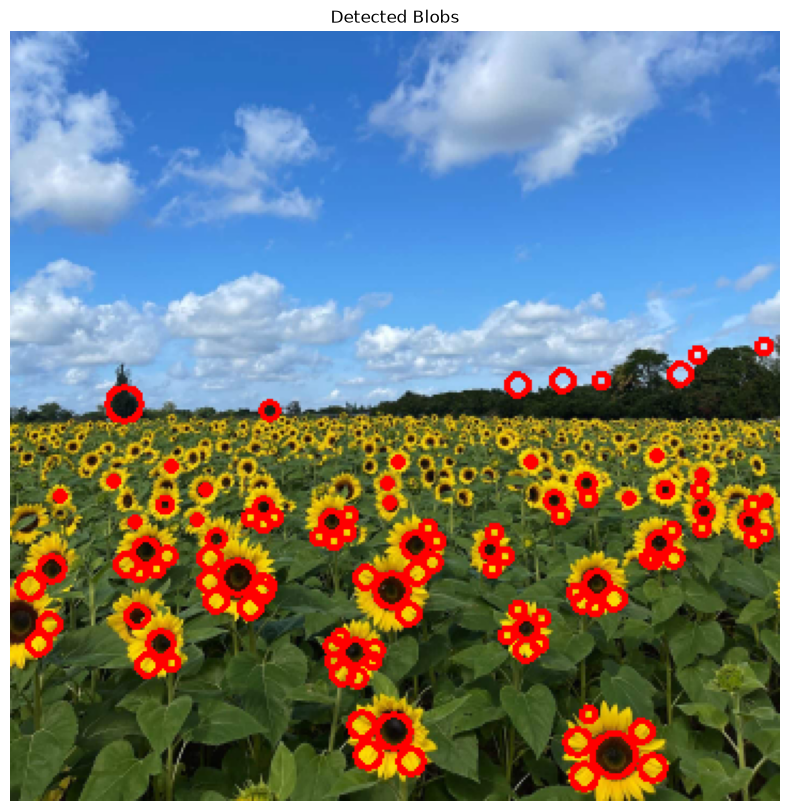

Largest detected circles:
Center (x, y) | Radius | Sigma
(282, 338) |  10.79 |   7.63
( 53, 174) |   8.63 |   6.10
(106, 255) |   8.63 |   6.10
(178, 261) |   8.63 |   6.10
(179, 327) |   8.63 |   6.10
(189, 240) |   6.91 |   4.88
( 63, 243) |   6.91 |   4.88
( 19, 251) |   6.91 |   4.88
(274, 258) |   6.91 |   4.88
(  9, 259) |   6.91 |   4.88

Sigma range: 1.60 to 36.38


In [7]:
#Importing the image
im_01 = cv.imread('the_berry_farms_sunflower_field.jpeg', cv.IMREAD_REDUCED_GRAYSCALE_4)

#Defining the number of scale levels
sigma_list = [1.6 * (1.25 ** i) for i in range(15)]

#Blank 3D space to store images
scale_space = np.zeros((im_01.shape[0], im_01.shape[1], len(sigma_list)), dtype=np.float64)

#Looping through the sigma values to store the image
for layer_index, sigma in enumerate(sigma_list):

    k = int(3*sigma)

    x = np.arange(-k, k + 1)
    y = np.arange(-k, k + 1)
    x, y = np.meshgrid(x, y) 

    g_xy = (1/(2*np.pi*sigma**2)) * np.exp(-(x**2 + y**2)/(2*sigma**2))

    #Laplacian of gaussian
    # first derivatives
    gx = np.gradient(g_xy, axis=1)
    gy = np.gradient(g_xy, axis=0)

    # second derivatives
    g_xx = np.gradient(gx, axis=1)
    g_yy = np.gradient(gy, axis=0)

    laplacian_of_gaussian = (sigma**2)*(g_xx + g_yy)

    #Applying the filter to the image
    im_laplace = cv.filter2D(im_01, cv.CV_64F, laplacian_of_gaussian)

    #Storing the image
    scale_space[:, :, layer_index] = im_laplace

#3D non maximum supression
def NMS_3D (image_block):

    #Blank image_block
    block = np.zeros((image_block.shape[0], image_block.shape[1], image_block.shape[2]), dtype=np.float64)

    #Getting the dimensions of the block
    rows, columns, height = np.shape(image_block)

    #Neighbours
    neighbours = [
                (-1, -1, -1), (-1, 0, -1), (-1, 1, -1),
                ( 0, -1, -1), ( 0, 0, -1), ( 0, 1, -1),
                ( 1, -1, -1), ( 1, 0, -1), ( 1, 1, -1) 
            ,
                  
                (-1, -1, 0), (-1, 0, 0), (-1, 1, 0),
                ( 0, -1, 0),             ( 0, 1, 0),
                ( 1, -1, 0), ( 1, 0, 0), ( 1, 1, 0) 
            , 
                  
                (-1, -1, 1), (-1, 0, 1), (-1, 1, 1),
                ( 0, -1, 1), ( 0, 0, 1), ( 0, 1, 1),
                ( 1, -1, 1), ( 1, 0, 1), ( 1, 1, 1) 
            ]


    #Squaring the image block to remove the negative values
    squared_image_block = np.multiply(image_block, image_block)

    #Adding a threshold to avoid unnesssary calculations
    threshold = 0.5 * squared_image_block.max()

    for i in range(1, rows - 1):
        for j in range(1, columns - 1):
            for k in range(1, height - 1):


                magnitude = squared_image_block[i, j, k]
                local_max_coordinates = [i, j, k]
                is_local_max = True

                #Ignoring the loop when when the value is too weak
                if magnitude < threshold :
                    continue

                for di, dj, dk in neighbours:

                    ni = i + di
                    nj = j + dj
                    nk = k + dk

                    if magnitude < squared_image_block[ni, nj, nk]:
                        is_local_max = False
                        break

                #If the center survives save the point
                if is_local_max:
                    block[i, j, k] = 255

    return block

#Image block after NMS 
scale_space_nms = NMS_3D(scale_space)

#Getting the indices of the non suppressed points
non_zero_values = np.argwhere(scale_space_nms > 0)

#Creating an image to draw colourd circles
im_with_blobs = cv.imread('the_berry_farms_sunflower_field.jpeg', cv.IMREAD_REDUCED_COLOR_4)

#Itarting through the non zero points to draw circles
for point in non_zero_values:

    #Format , (row, column, scale_index)
    y = point[0]
    x = point[1]
    scale_index = point[2]

    sigma = sigma_list[scale_index]

    #Radius
    radius = int(sigma * np.sqrt(2))

    #Drawing the circle
    cv.circle(im_with_blobs, (x, y), radius, (0, 0, 255), 2)

# Plot the final masterpiece
plt.figure(figsize=(15, 10))
plt.imshow(cv.cvtColor(im_with_blobs, cv.COLOR_BGR2RGB))
plt.title("Detected Blobs")
plt.axis('off')
plt.show()

#Collect the parameters of the detected circles
detected_circles = []

for y, x, scale_index in non_zero_values:
    sigma = sigma_list[scale_index]
    radius = sigma * np.sqrt(2)

    detected_circles.append((x, y, radius, sigma))

#Sort circles by radius, largest first
detected_circles.sort(key=lambda circle: circle[2], reverse=True)

#Printing the values
print("Largest detected circles:")
print("Center (x, y) | Radius | Sigma")

for x, y, radius, sigma in detected_circles[:10]:
    print(f"({x:3d}, {y:3d}) | {radius:6.2f} | {sigma:6.2f}")

print(f"\nSigma range: {sigma_list[0]:.2f} to {sigma_list[-1]:.2f}")
